# Лабораторна робота №6
**Класифікація. Запобігання перенавчанню**


Дані: [Diabetes Prediction Dataset (Kaggle)](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset)

## 1. Завантаження та перегляд даних

In [1]:
!pip -q install kagglehub imbalanced-learn xgboost lightgbm catboost

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
sns.set_theme(style="whitegrid")

In [3]:
folder = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
df = pd.read_csv(os.path.join(folder, "diabetes_prediction_dataset.csv"))
print("Розмір:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Розмір: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [4]:
df.info()
print("Типи даних:")
print(df.dtypes)
print("Стать:")
print(df["gender"].value_counts())
print("Історія паління:")
print(df["smoking_history"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
Типи даних:
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes

Баланс до очищення:
diabetes
0    91500
1     8500
Name: count, dtype: int64
Пропуски:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64
Дублікати: 3854
Після очищення: (96146, 9)
diabetes
0    87664
1     8482
Name: count, dtype: int64


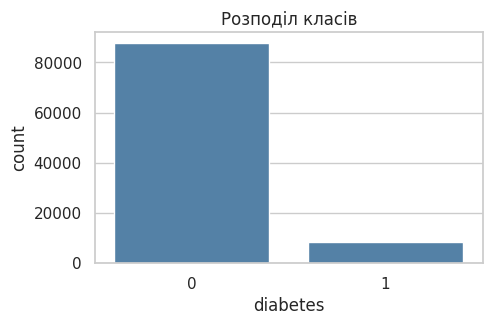

In [5]:
print("Баланс до очищення:")
print(df["diabetes"].value_counts())
print("Пропуски:")
print(df.isna().sum())
print("Дублікати:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Після очищення:", df.shape)
print(df["diabetes"].value_counts())
fig, ax = plt.subplots(figsize=(5, 3))
sns.countplot(data=df, x="diabetes", ax=ax, color="steelblue")
ax.set_title("Розподіл класів")
plt.show()

## 2. Розподіл вибірок та аналіз ознак

In [6]:
X = df.drop(columns="diabetes")
y = df["diabetes"]
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train = pd.get_dummies(X_train_raw, columns=["gender", "smoking_history"], dtype=int)
X_test = pd.get_dummies(X_test_raw, columns=["gender", "smoking_history"], dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print("Навчальна:", X_train.shape, "Тестова:", X_test.shape)
display(X_train.describe().T)

Навчальна: (76916, 15) Тестова: (19230, 15)


,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Female,76916.0,0.582675,0.493121,0.00,0.00,1.00,1.00,1.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_No Info,76916.0,0.342022,0.474390,0.00,0.00,0.00,1.00,1.00


Кореляції з ціллю (лише train):
blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_No Info       -0.113053
smoking_history_former         0.096162
gender_Male                    0.040650
gender_Female                 -0.040533
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
Name: diabetes, dtype: float64


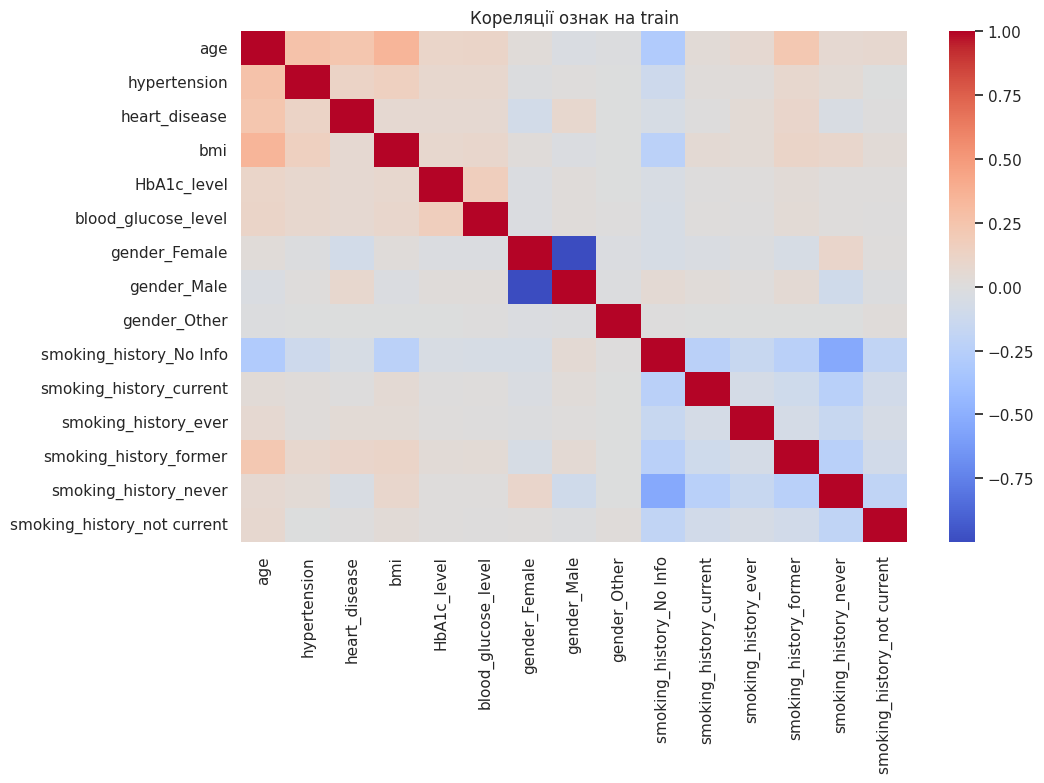

In [7]:
corr_y = X_train.assign(diabetes=y_train).corr(numeric_only=True)["diabetes"].drop("diabetes")
print("Кореляції з ціллю (лише train):")
print(corr_y.sort_values(key=abs, ascending=False))
plt.figure(figsize=(11, 8))
sns.heatmap(X_train.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Кореляції ознак на train")
plt.tight_layout()
plt.show()

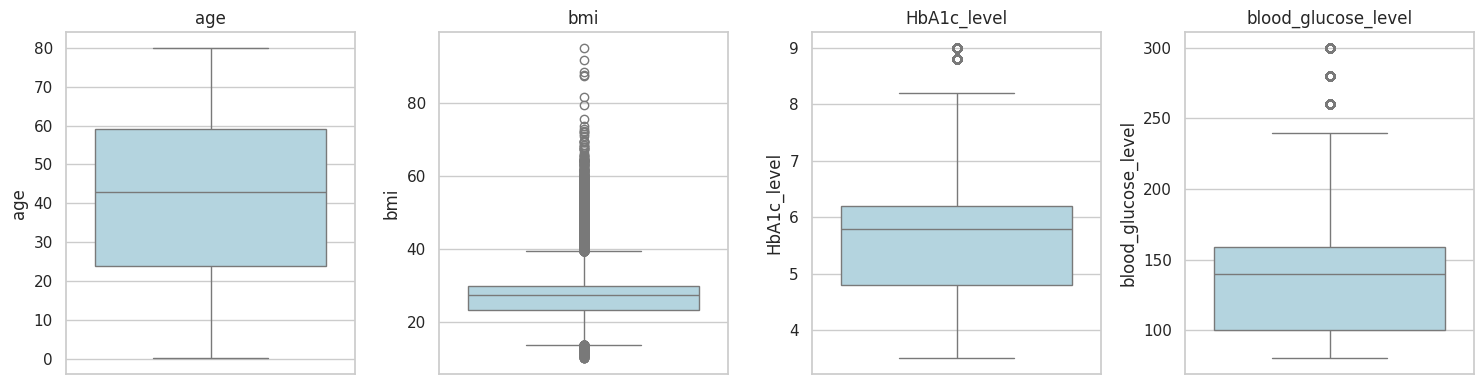

Асиметрія (train):
age                   -0.061
bmi                    1.005
HbA1c_level           -0.056
blood_glucose_level    0.831
dtype: float64
Пропуски train/test: 0 0
Викиди не видаляємо: високі значення HbA1c та глюкози можуть бути важливими.


In [8]:
continuous_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=X_train[col], ax=ax, color="lightblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()
print("Асиметрія (train):")
print(X_train[continuous_cols].skew().round(3))
print("Пропуски train/test:", int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))
print("Викиди не видаляємо: високі значення HbA1c та глюкози можуть бути важливими.")

## 3. Масштабування, SMOTE та базові моделі

In [9]:
scaler = StandardScaler()
train_scaled = scaler.fit_transform(X_train)
test_scaled = scaler.transform(X_test)
smote = SMOTE(random_state=42)
X_bal, y_bal = smote.fit_resample(train_scaled, y_train)
print("До SMOTE:", y_train.value_counts().to_dict())
print("Після SMOTE:", pd.Series(y_bal).value_counts().to_dict())

До SMOTE: {0: 70130, 1: 6786}
Після SMOTE: {0: 70130, 1: 70130}


In [10]:
models = {"LogisticRegression": LogisticRegression(max_iter=1200, random_state=42), "RidgeClassifier": RidgeClassifier(), "SGDClassifier": SGDClassifier(random_state=42, max_iter=1200), "SVC": SVC(kernel="linear", random_state=42)}

Для швидшого навчання базових моделей беремо 16831 збалансованих train-об'єктів

 LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



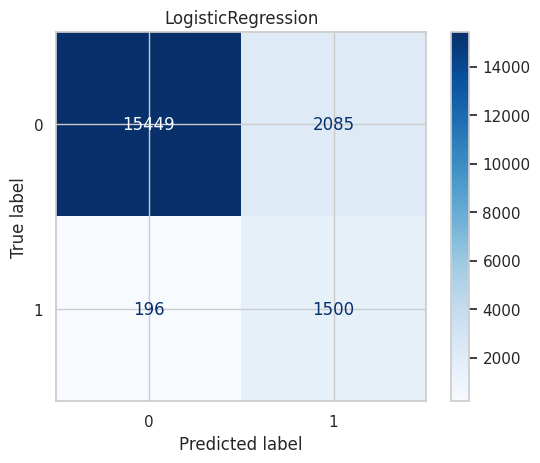


 RidgeClassifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230



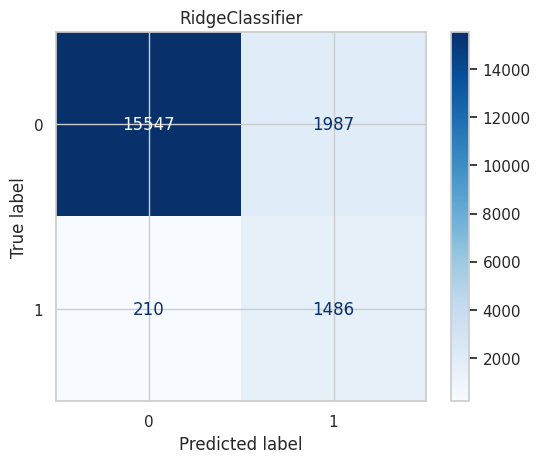


 SGDClassifier
              precision    recall  f1-score   support

           0       0.99      0.85      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



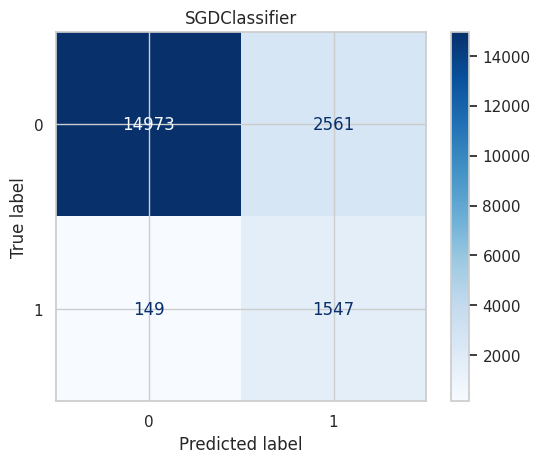


 SVC
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.89      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



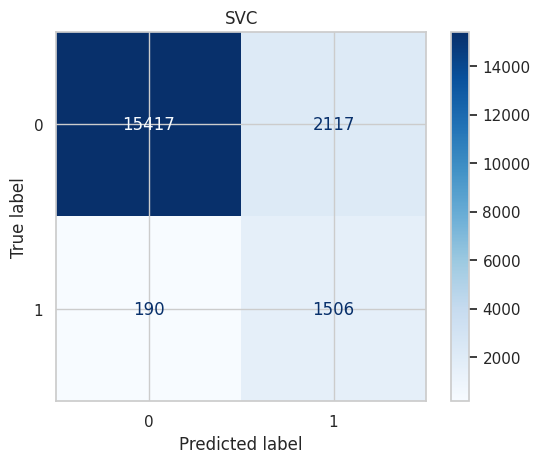

In [11]:
X_fit, _, y_fit, _ = train_test_split(X_bal, y_bal, train_size=0.12, stratify=y_bal, random_state=42)
print("Для швидшого навчання базових моделей беремо", len(y_fit), "збалансованих train-об'єктів")
baseline = {}
for name, estimator in models.items():
    estimator.fit(X_fit, y_fit)
    predicted = estimator.predict(test_scaled)
    baseline[name] = {"f1": f1_score(y_test, predicted), "recall": recall_score(y_test, predicted)}
    print("\n", name)
    print(classification_report(y_test, predicted, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, cmap="Blues", values_format="d")
    plt.title(name)
    plt.show()

## 4. Оптимізація гіперпараметрів

In [12]:
param_grids = {"LogisticRegression": {"model__C": [0.1, 1.0], "model__solver": ["liblinear"]}, "RidgeClassifier": {"model__alpha": [0.5, 2.0]}, "SGDClassifier": {"model__loss": ["hinge", "log_loss"], "model__penalty": ["l2"]}, "SVC": {"model__C": [0.5, 1.0], "model__kernel": ["linear"]}}

LogisticRegression: F1 CV=0.6622; параметри={'model__C': 1.0, 'model__solver': 'liblinear'}
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



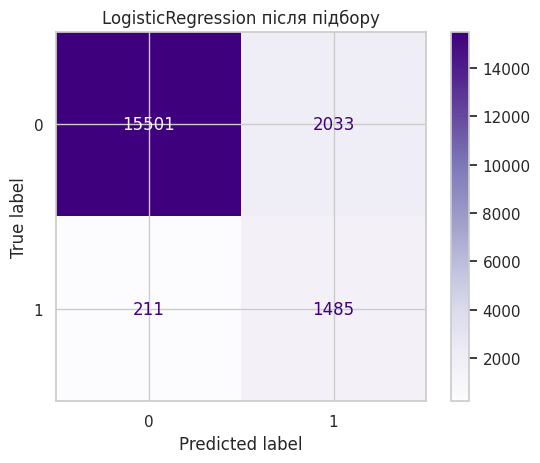

RidgeClassifier: F1 CV=0.5471; параметри={'model__alpha': 2.0}
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.87      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230



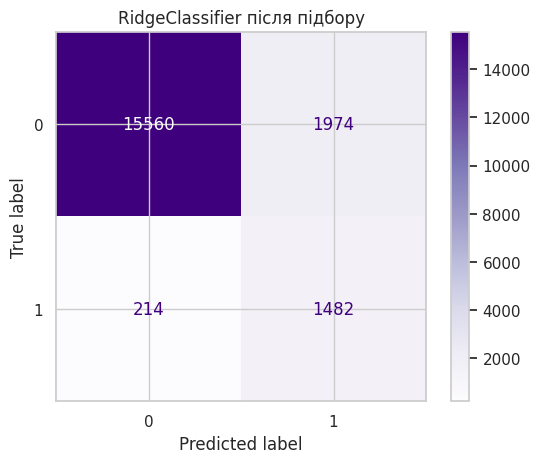

SGDClassifier: F1 CV=0.5008; параметри={'model__loss': 'log_loss', 'model__penalty': 'l2'}
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



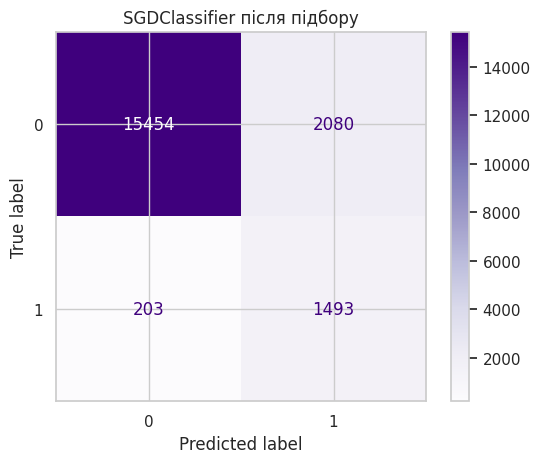

SVC: F1 CV=0.4924; параметри={'model__C': 0.5, 'model__kernel': 'linear'}
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



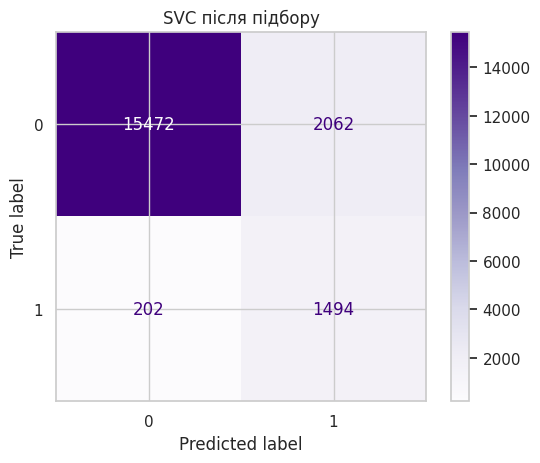

In [13]:
best_models = {}
best_scores = {}
chosen_params = {}
X_search, _, y_search, _ = train_test_split(X_train, y_train, train_size=0.18, stratify=y_train, random_state=42)
for name, estimator in models.items():
    pipeline = Pipeline([("scale", StandardScaler()), ("smote", SMOTE(random_state=42)), ("model", estimator)])
    search = HalvingGridSearchCV(pipeline, param_grids[name], cv=3, scoring="f1", min_resources=300, factor=2, n_jobs=-1)
    search.fit(X_search, y_search)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    chosen_params[name] = search.best_params_
    print(f"{name}: F1 CV={search.best_score_:.4f}; параметри={search.best_params_}")
    print(classification_report(y_test, search.predict(X_test), zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, search.predict(X_test), cmap="Purples", values_format="d")
    plt.title(name + " після підбору")
    plt.show()

In [14]:
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]
print("Найкраща за CV:", best_name, "F1:", round(best_scores[best_name], 4))
selected = X_test.sample(n=10, random_state=42)
comparison = pd.DataFrame({"Індекс": selected.index, "Справжній клас": y_test.loc[selected.index].values, "Прогноз": best_model.predict(selected)}).set_index("Індекс")
display(comparison)

Найкраща за CV: LogisticRegression F1: 0.6622


,Справжній клас,Прогноз
Індекс,,
35493,0,0
29438,0,0
29287,0,1
11752,0,0
95450,0,0
26415,0,0
51899,0,0
67326,0,0
8881,0,1


## 5. Додаткове завдання: XGBoost, LightGBM, CatBoost


XGBoost
              precision    recall  f1-score   support

           0       0.98      0.95      0.97     17534
           1       0.61      0.83      0.70      1696

    accuracy                           0.94     19230
   macro avg       0.80      0.89      0.83     19230
weighted avg       0.95      0.94      0.94     19230



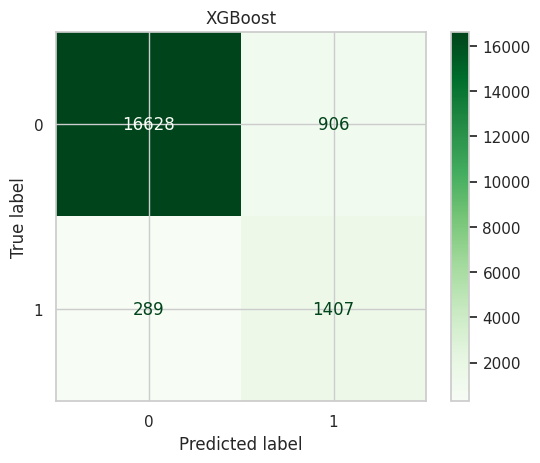

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



LightGBM
              precision    recall  f1-score   support

           0       0.98      0.97      0.98     17534
           1       0.74      0.78      0.76      1696

    accuracy                           0.96     19230
   macro avg       0.86      0.88      0.87     19230
weighted avg       0.96      0.96      0.96     19230



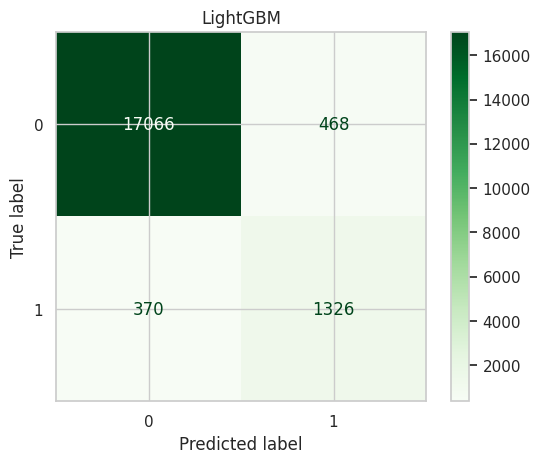


CatBoost
              precision    recall  f1-score   support

           0       0.98      0.96      0.97     17534
           1       0.66      0.81      0.73      1696

    accuracy                           0.95     19230
   macro avg       0.82      0.89      0.85     19230
weighted avg       0.95      0.95      0.95     19230



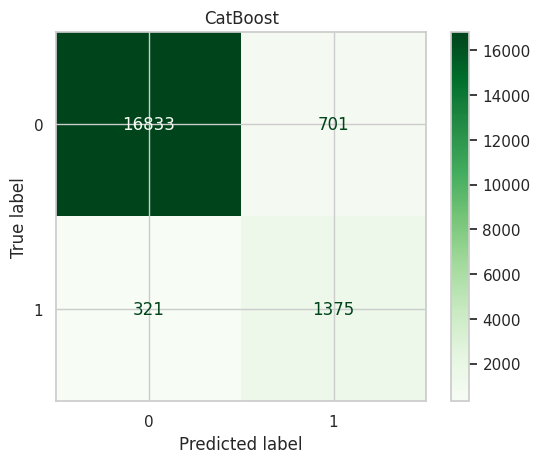

In [15]:
extra_models = {
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.08, eval_metric="logloss", random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=100, max_depth=5, learning_rate=0.08, random_state=42, verbosity=-1),
    "CatBoost": CatBoostClassifier(iterations=120, depth=5, learning_rate=0.08, random_seed=42, verbose=False)
}
extra_scores = {}
for title, model in extra_models.items():
    model.fit(X_fit, y_fit)
    predicted = model.predict(test_scaled)
    extra_scores[title] = {"f1": f1_score(y_test, predicted), "recall": recall_score(y_test, predicted)}
    print("\n" + title)
    print(classification_report(y_test, predicted, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, cmap="Greens", values_format="d")
    plt.title(title)
    plt.show()

## 6. Висновки

## Висновки

Під час роботи я підготував дані для класифікації та порівняв кілька моделей. У наборі після видалення дублікатів залишилося 96 146 записів. Випадків діабету значно менше за інші, тому для навчання використовував SMOTE. Серед базових алгоритмів найкращий F1 для класу 1 показав RidgeClassifier — 0,575, а під час підбору параметрів найвищий результат кросвалідації отримав SGDClassifier (0,593). Проте з додаткових моделей LightGBM спрацював помітно краще: F1 для класу діабету — 0,760, точність класифікації — 0,96. Я побачив, що висока загальна accuracy ще не означає однаково добру якість для обох класів, особливо за такого дисбалансу.